In [1]:
import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

####################
# DIPY_HOME should be set prior to import of dipy to make sure all downloads point to the right folder
####################
os.environ["DIPY_HOME"] = "/home/jovyan/Data"


#############################
# Loading fsl and freesurfer within Neurodesk
# You can find the list of available other modules by clicking on the "Softwares" tab on the left
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Load all relevant libraries for the lab
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import mne_nirs
import nilearn
from nilearn.datasets import fetch_development_fmri

import mne
import mne_nirs

import xml.etree.ElementTree as ET
import os.path as op
import nibabel as nib
import glob

!pip install antspyx
import ants

import openneuro
from mne.datasets import sample
from mne_bids import BIDSPath, read_raw_bids, print_dir_tree, make_report

# Useful imports to define the direct download function below
import requests
import urllib.request
from tqdm import tqdm


# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json
fMRI_data_root = op.join(notebook_dir, 'fMRI', 'tfMRI_LANGUAGE_LR')
fMRI_data_filepath = op.join(fMRI_data_root, 'tfMRI_LANGUAGE_LR.nii.gz')

  Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.3 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
ERROR: Could not install packages due to an OSError: [Errno 13] Permission denied: '/opt/conda/lib/python3.13/site-packages/scipy-1.18.1.dist-info/'
Consider using the `--user` option or check the permissions.



In [2]:
%gui wx


(ipykernel_launcher.py:9282): dbind-WARNING **: 15:26:30.238: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1333487151/at-spi/bus_100: No such file or directory


In [3]:
################
# Start FSLeyes (very neat tool to visualize MRI data of all sorts) within Python
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

15:26:34: Debug: Adding duplicate image handler for 'Windows bitmap file'
15:26:34: Debug: Adding duplicate animation handler for '1' type
15:26:34: Debug: Adding duplicate animation handler for '2' type
15:26:34: Debug: Adding duplicate image handler for 'Windows bitmap file'
15:26:34: Debug: Adding duplicate animation handler for '1' type
15:26:34: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:9282): Gtk-CRITICAL **: 15:26:35.020: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:9282): Gtk-CRITICAL **: 15:26:37.225: gtk_window_resize: assertion 'width > 0' failed


316


Text(0, 0.5, 'Mean voxel intensity')

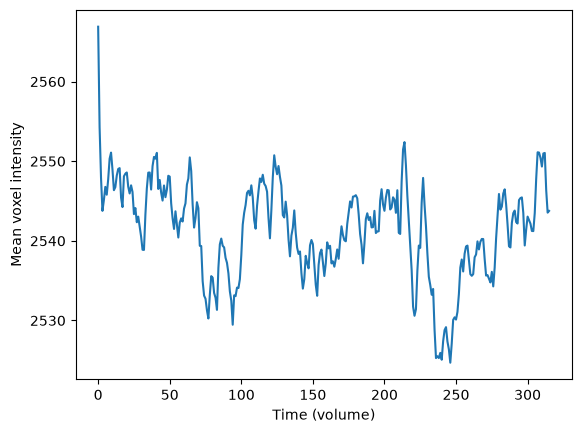

In [4]:
### Removing problematic volumes
# 1) remove first volumes, we need to see when the signal settles
import matplotlib.pyplot as plt
import nibabel as nib

fMRI_data_full = nib.load(op.join(fMRI_data_filepath)).get_fdata()
total_nb_volumes = fMRI_data_full.shape[3]
print(total_nb_volumes)
plt.plot(fMRI_data_full.mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

In [5]:
## We see the first volume is a big drop, but as we did in lab 3, we will remove the first 10 to be sure.
file_to_trim = glob.glob(fMRI_data_filepath)[0]
derivatives_folder = op.join(notebook_dir, 'derivatives')
output_target = op.join(derivatives_folder, 'tfMRI_LANGUAGE_LR_settled.nii.gz')

# For this, knowing that there are originally 184 volumes and that you want to throw away the first 10, please fill in
# the following variables
start_vol = 9 # Where should we start? (First volume is 0, not 1 !)
number_of_volumes = total_nb_volumes - start_vol

# Function creating new nifti with trimmed number of volumes
fslroi(file_to_trim, output_target, str(start_vol), str(number_of_volumes))
print(f"You kept {nib.load(output_target).shape[-1]} volumes.")

You kept 307 volumes.


In [6]:
from fsl.wrappers import mcflirt

# Input: your fMRI file
fMRI_settled_data_filepath = output_target

# Output: a derivatives folder next to the data
preproc_root = op.join(notebook_dir, 'derivatives')
os.makedirs(preproc_root, exist_ok=True)

path_moco_data = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco')

mcflirt(infile=fMRI_settled_data_filepath, o=path_moco_data, plots=True, report=True, dof=6, mats=True)

Processed data will be saved as /data/Desktop/myfiles/NSSP_MiniProjects/derivatives/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [153] to 8 mm pixels
Registering volumes ... [154][155][156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][

refnum = 153
Original_refvol = -1


Registering volumes ... [154][155][156][157][158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][119][118][117][116][115][114][113][112][111][

{}

In [7]:
print_dir_tree(preproc_root, max_depth=5)

|derivatives/
|--- T1w_brain.nii.gz
|--- T1w_brain_mask.nii.gz
|--- T1w_fast_mixeltype.nii.gz
|--- T1w_fast_pve_0.nii.gz
|--- T1w_fast_pve_1.nii.gz
|--- T1w_fast_pve_2.nii.gz
|--- T1w_fast_pveseg.nii.gz
|--- T1w_fast_seg.nii.gz
|--- tfMRI_LANGUAGE_LR_moco-Copy1.nii.gz
|--- tfMRI_LANGUAGE_LR_moco.nii.gz
|--- tfMRI_LANGUAGE_LR_moco.par
|--- tfMRI_LANGUAGE_LR_settled.nii.gz
|--- tfMRI_LANGUAGE_LR_moco.mat/
|------ MAT_0000
|------ MAT_0001
|------ MAT_0002
|------ MAT_0003
|------ MAT_0004
|------ MAT_0005
|------ MAT_0006
|------ MAT_0007
|------ MAT_0008
|------ MAT_0009
|------ MAT_0010
|------ MAT_0011
|------ MAT_0012
|------ MAT_0013
|------ MAT_0014
|------ MAT_0015
|------ MAT_0016
|------ MAT_0017
|------ MAT_0018
|------ MAT_0019
|------ MAT_0020
|------ MAT_0021
|------ MAT_0022
|------ MAT_0023
|------ MAT_0024
|------ MAT_0025
|------ MAT_0026
|------ MAT_0027
|------ MAT_0028
|------ MAT_0029
|------ MAT_0030
|------ MAT_0031
|------ MAT_0032
|------ MAT_0033
|------ MAT_003

In [8]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(fMRI_data_filepath)
fsleyesDisplay.load(path_moco_data)

In [9]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco.par'))
mot_params

,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,0.000316,-0.000213,0.000144,-0.042112,-0.014714,0.032973
1,0.000008,-0.000026,0.000598,-0.031466,0.004794,-0.033811
2,-0.000041,-0.000261,0.000309,-0.032421,0.023103,-0.058697
3,0.000150,-0.000324,0.000051,-0.035766,-0.018788,0.031094
4,-0.000192,-0.000471,0.000040,-0.032432,0.012152,0.033224
...,...,...,...,...,...,...
302,0.000708,-0.000182,-0.000021,-0.031232,-0.028393,0.010999
303,0.000411,-0.000182,-0.000021,0.045673,-0.020540,0.039338
304,0.000791,-0.000337,-0.000076,-0.031231,-0.020642,0.026120
305,0.000191,-0.000182,-0.000021,-0.031232,-0.022710,0.037704


In [10]:
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    # To know this one, we can remember the definition of the radian!
    # Indeed, let the radian be theta, the arc length be s and the radius be r.
    # Then theta = s / r
    # We want to determine here s, for a sphere of 50mm radius and knowing theta. Easy enough!
    
    # Another way to think about it is through the line integral along the circle.
    # Integrating from 0 to theta with radius 50 will give you, unsurprisingly, r0 theta.
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

In [11]:
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

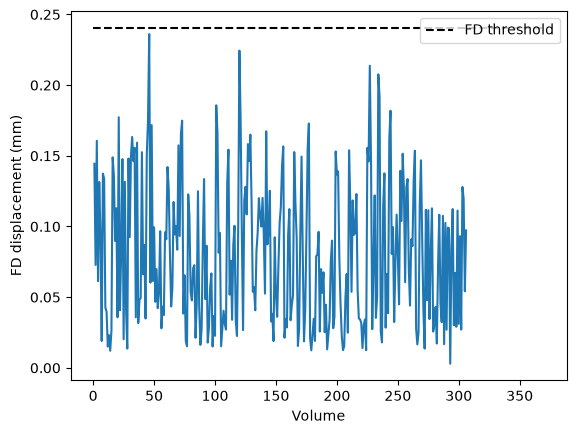

In [12]:
#%matplotlib inline
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.legend()
plt.show()

In [13]:
print(f"Indices of frames above threshold: {(np.where(fd > threshold)[0] + 1).tolist()}")

Indices of frames above threshold: []


In [14]:
#The patient did not have anz significant movement. The FWD is alwazs below the threshold

In [15]:
## NOW WE DO Registration from Functional to anatomical

In [19]:
# We need skull stripped T1 & perform tissue segmentation for registration
import subprocess
whole_t1 = os.path.join(notebook_dir, 'T1', 'T1w.nii.gz')
skull_stripped_t1 = op.join(derivatives_folder, 'T1w_brain')
white_matter_segmentation = op.join(derivatives_folder, "T1w_fast_pve_2") # two is white matter
## use motion corrected as source for registration
epi_source = path_moco_data
output_func_2_anat = op.join(derivatives_folder, "tfMRI_LANGUAGE_LR_reg_moco_to_anat")

#use the middle moco volume as reference, use fslroi to extract it
ref_vol_name = op.join(derivatives_folder, "tfMRI_LANGUAGE_LR_moco_midvol")
fslroi(path_moco_data, ref_vol_name, str(number_of_volumes // 2), '1')
# run the registration
subprocess.run(['epi_reg','--epi={}'.format(ref_vol_name), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), 
                '--out={}'.format(output_func_2_anat),
               '--wmseg={}'.format(white_matter_segmentation)])


FLIRT pre-alignment
Running BBR
0.939416 0.999473 -0.032125 -0.004779 0.000000 0.031723 0.997150 -0.068452 0.000000 0.006965 0.068264 0.997643 0.000000 -6.812083 -2.996872 9.966999 1.000000 


CompletedProcess(args=['epi_reg', '--epi=/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/tfMRI_LANGUAGE_LR_moco_midvol', '--t1=/data/Desktop/myfiles/NSSP_MiniProjects/T1/T1w.nii.gz', '--t1brain=/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/T1w_brain', '--out=/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/tfMRI_LANGUAGE_LR_reg_moco_to_anat', '--wmseg=/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/T1w_fast_pve_2'], returncode=0)

In [20]:
## visualize alignement
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(output_func_2_anat)

In [21]:
## now we do smoothing, but how to choose fwhm ?

In [24]:
fwhm = 6
cmd = 'fslmaths {} -s {} {}_smoothed-{}mm'.format(output_func_2_anat, fwhm/2.3548, output_func_2_anat, fwhm)
smoothed_fmri_filename = '{}_smoothed-{}mm'.format(output_func_2_anat, fwhm)
subprocess.run(['fslmaths',output_func_2_anat, '-s', str(fwhm/2.3548), smoothed_fmri_filename])

CompletedProcess(args=['fslmaths', '/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/tfMRI_LANGUAGE_LR_reg_moco_to_anat', '-s', '2.547987090198743', '/data/Desktop/myfiles/NSSP_MiniProjects/derivatives/tfMRI_LANGUAGE_LR_reg_moco_to_anat_smoothed-6mm'], returncode=0)

In [ ]:
## visualize smoothed brain fmri

In [25]:
fsleyesDisplay.load(smoothed_fmri_filename)